# Desenvolvimento do modelo de Regressão Logística - Binário
---

## A) Importando as Bibliotecas e Pacotes a serem usados
---

### 1. Pacotes baixados:
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, RocCurveDisplay
from xgboost import XGBClassifier

### 2. Pacotes Predexan:
---

In [2]:
import sys
import os

caminho_predexan = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if caminho_predexan not in sys.path:
    sys.path.append(caminho_predexan)

print(f"Buscando em: {caminho_predexan}")
print(f"Pastas encontradas: {os.listdir(caminho_predexan)}")

import predexan.graficos as pg
import predexan.metricas as pm
import predexan.preproc as pp

Buscando em: C:\Users\rmaca\PUC_eixo7\projeto\pmv-si-2026-1-pe7-t3-g1-pesquisaexperimentacao-2026-1\src
Pastas encontradas: ['.ipynb_checkpoints', 'analise_exploratoria_pre_processamento', 'dataset', 'imagens', 'modelos', 'predexan', 'README.md']


## B) Determinando os Dataframes à partir das bases de dados pré-processados
---

### 1. Determinando df_treino
---

In [3]:
df_treino = pd.read_parquet('../../dataset/pre_processado/treino_pre_processado.parquet')
df_treino.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 36 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 96822 non-null  float64
 1   protocolo_rede                      96822 non-null  float64
 2   servico_conexao                     96822 non-null  float64
 3   estado_conexao                      96822 non-null  float64
 4   num_pacotes_origem                  96822 non-null  float64
 5   num_pacotes_destino                 96822 non-null  float64
 6   total_bytes_origem                  96822 non-null  float64
 7   total_bytes_destino                 96822 non-null  float64
 8   taxa_pacote                         96822 non-null  float64
 9   carga_origem                        96822 non-null  float64
 10  carga_destino                       96822 non-null  float64
 11  pacotes_perdidos_origem             96822 non-null  floa

### 2. Deteminando df_teste
---

In [4]:
df_teste = pd.read_parquet('../../dataset/pre_processado/teste_pre_processado.parquet')
df_teste.info()

<class 'pandas.DataFrame'>
Index: 49971 entries, 0 to 82328
Data columns (total 36 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 49971 non-null  float64
 1   protocolo_rede                      49971 non-null  float64
 2   servico_conexao                     49971 non-null  float64
 3   estado_conexao                      49971 non-null  float64
 4   num_pacotes_origem                  49971 non-null  float64
 5   num_pacotes_destino                 49971 non-null  float64
 6   total_bytes_origem                  49971 non-null  float64
 7   total_bytes_destino                 49971 non-null  float64
 8   taxa_pacote                         49971 non-null  float64
 9   carga_origem                        49971 non-null  float64
 10  carga_destino                       49971 non-null  float64
 11  pacotes_perdidos_origem             49971 non-null  float

## C) Separando os valores em teste e treino
---

Nessa seção, serão separadas as `features` do `target`, tanto para a base de testes quanto de treino.

Há duas possibilidades claras de `target`, presentes nos datasets, dado o cenário de `Classificação` e `Regressão Logística`: `label`e `categoria_ataque.

A primeira retornaria um diagnóstico apontado se há uma probabilidade alta ou baixa de haver um ataque, de maneira geral. Já a segunda, retornaria a probabilidade de haver um ataque específico dentro de suas dez classes.

A escolha do target se embasa tanto na especialização da resposta, quanto no desempenho e custo computacional do modelo. Dessa forma, ao escolher `label`, a resposta é mais simples, mas continua sendo de grande valor, e o custo computacional é muito inferior. Já a escolha de `categoria_ataque`, traz uma resposta mais especializada e de maior qualidade para o usuário, contudo o custo computacional se mostrou alto.

A escolha de target **provisória** é `label` por conta da razão utilidade/custo computacional, mas ainda será ***conversado com o professor*** a possibilidade de se voltar a usar `categoria_ataque`, mesmo que este não tenha sido processado de forma eficiente pelas máquinas a disposição, em primeiro momento. 

### 1. Atributos do df_treino
---

In [5]:
# Features
X_treino = df_treino.drop(columns=['label', 'categoria_ataque'])

# Target
y_treino = df_treino['label']

### 2. Atributos do df_teste
---

In [6]:
# Features
X_teste = df_teste.drop(columns=['label', 'categoria_ataque'])

# Target
y_teste = df_teste['label']

## D) Desenvolvimento do Modelo de XGBoost Classifier
---

### 1. Aplicação da classe SMOTE para balanceamento de classes nas variáveis de treino
---

- Target **label**:

O uso da classe `SMOTE`se mostra **injustificado** para o target `label` uma vez que ele já está naturalmente balanceado na base de treino.

In [7]:
# df_treino['label'].value_counts()

### 2. Treino do modelo
---

#### 2.1. Instanciando a classe XGBClassifier

In [8]:
modelo = XGBClassifier(objective='binary:logistic', eval_metric='error', learning_rate=0.2, max_depth=3, n_estimators=30, scale_pos_weight=1.72)

**Explicando os parâmetros utilizados em XGBClassifier:**

- `objective='binary:logistic'` -> Define que o problema é de `classificação binária`, ou seja, prever duas classes (True/False, 0/1)
  
- `eval_metric='error'` -> Métrica de avaliação usada durante o treino. Aqui, “error” significa a taxa de erro de classificação (proporção de previsões incorretas)

- `learning_rate=0.3` -> Também chamado de eta. Controla o tamanho do passo em cada atualização. Valores menores tornam o aprendizado mais lento, mas podem melhorar a generalização

- `max_depth=3` -> Profundidade máxima das árvores de decisão. Árvores rasas (como 1) reduzem complexidade e ajudam a evitar overfitting (decorar os dados), mas podem limitar a capacidade de capturar relações complexas.

- `n_estimators=120` -> Número de árvores (ou rodadas de boosting) que serão treinadas. Mais árvores aumentam a capacidade do modelo, mas também o risco de overfitting se não houver regularização. Havia atribuído 10, mas aumentei o número de árvores para aumentar precisão

- `scale_pos_weight=1.72` -> Equilibra os pesos positivos e negativos. O valor de 1.72 representa a razão (proporção) entre a quantidade de registros da classe negativa (tráfego normal) e a classe positiva (ataques) para garantir que o algoritmo não ignore os ataques devido à maior frequência de tráfego legítimo, equilibrando a sensibilidade do modelo. 


#### 2.2. Treinando o modelo
---

Para o treino do modelo, é usada a expressão `modelo.fit(X_treino, y_treino)`. Será rodado em conjunto com a função `imprimir_tempo()` do módulo `metricas` do pacote `Predexan`, para poder ter o tempo de processamento registrado: 

In [9]:
pm.imprimir_desempenho(modelo.fit,X_treino, y_treino)

- RELATÓRIO DE DESEMPENHO:

    1. Tempo:

      Tempo de processamento: 0.4500 segundos ou 0.01 minutos.

    2. Uso de Memória RAM:

      Atual: 108561 Bytes ou 0.10 MegaBytes | Pico: 973409 Bytes ou 0.93 MegaBytes.




XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='error', feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.2, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=30, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

### 3. Realização de predições com os dados de teste
---

Para a predição probabilística, é usado o método `predict_proba()` na seguinte expressão: `modelo.predict_proba(X_teste)`. Para a predição binária, é expresso da mesma forma, mas com o uso do método `predict()`. Ambas terão seu desempenho medido pela função `imprimir_desempenho()` de `Predexan`.

#### 3.1. Predição Probababilística
---

Para a predição probabilística, é usado o método `predict_proba()` na seguinte expressão: `modelo.predict_proba(X_teste)`

In [10]:
y_predicao_probabilistica = pm.imprimir_desempenho(modelo.predict_proba, X_teste)[:,1]

y_predicao_probabilistica = (y_predicao_probabilistica > 0.7).astype(int)

- RELATÓRIO DE DESEMPENHO:

    1. Tempo:

      Tempo de processamento: 0.0452 segundos ou 0.00 minutos.

    2. Uso de Memória RAM:

      Atual: 458324 Bytes ou 0.44 MegaBytes | Pico: 858508 Bytes ou 0.82 MegaBytes.




#### 3.2. Predição Binária
---

Para a Predição Binária, é usado o método `predict()` na seguinte expressão: `modelo.predict(X_teste)`

In [11]:
y_predicao_binaria = pm.imprimir_desempenho(modelo.predict, X_teste)

- RELATÓRIO DE DESEMPENHO:

    1. Tempo:

      Tempo de processamento: 0.0511 segundos ou 0.00 minutos.

    2. Uso de Memória RAM:

      Atual: 445210 Bytes ou 0.42 MegaBytes | Pico: 696355 Bytes ou 0.66 MegaBytes.




In [12]:
type(y_predicao_binaria)

numpy.ndarray

### 4. Desempenho do modelo
---

O modelo possui métricas de desempenho baseadas nos resultados dos testes, sendo essas: 

- `Pontuação` que traz a `Acurácia Geral`.
- `Matriz de Confusão` que traz os acertos e erros de inferência.
-  `Relatório de Classificação` que traz cálculos como `Precision`, `Recall` e `F1-Score`.
-  `Curva ROC AUC` que traz uma visualização gráfica.

#### 4.1. Matriz de Confusão
---

A `Matriz de Confusão` permite a visualização do desempenho do modelo, uma vez que mostra o total de predições `Verdadeiras Positivas (TP)`, `Verdadeiras Negativa (TN)`, `Falsas Positivas (FP)` e `Falsas Negativas (FN)`. No contexto do projeto, que visa a probailidade de `detecção de ameaças`, os alvos são sempre atingir ao máximo`TN` e `TP`, mas `FN` é o erro crítico, pois pode levar ao usuário da aplicação a ignorar a hipótese do ataque em sua máquina, podendo propiciar uma piora no caso, já que este pode deixar de buscar ajuda e manutenções e `FP` é o alarme falso. 

##### 4.1.1. Criação da Matriz de Confusão 
---

In [13]:
matriz_confusao = confusion_matrix(y_teste, y_predicao_binaria)

##### 4.1.2. Visualização da Matriz de Confusão 
---

<Axes: >

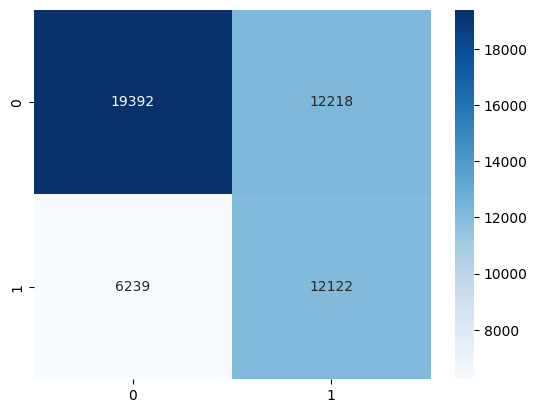

In [14]:
matriz_confusao = confusion_matrix(y_teste, y_predicao_probabilistica)
sns.heatmap(matriz_confusao, annot=True, fmt='d', cmap='Blues')

##### 4.1.3. Análises da Matriz de Confusão
---

In [15]:
(tn, fp), (fn, tp) = matriz_confusao
total = (tn+fn+tp+fp)

In [16]:
print(f'O total de predições de teste foi {total}.')

print(f'\n - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há {tn} casos que o modelo apontou como resultado negativo, corretamente. Representa {pm.calcular_percentual(tn, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há {fn} casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa {pm.calcular_percentual(fn, total):.2f}% do total de predições de teste.')
print(f'\n - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há {tp} casos em que o modelo apontou como resultado positivo, corretamente. Representa {pm.calcular_percentual(tp, total):.2f}% do total de predições de teste.')
print(f'\n - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há {fp} casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa {pm.calcular_percentual(fp, total):.2f}% do total de predições de teste.')
print(f'\n\nResultados:')

print(f'\n - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a {(tn + tp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((tn+tp), total):.2f}% do total de predições.')
print(f'\n - A quantidade de vezes que o modelo errou é expressa por FN + FP e é igual a {(fn + fp)}, de um total de {total}. Isto corresponde a, aproximadamente, {pm.calcular_percentual((fn+fp), total):.2f}% do total de predições.\n\n')

O total de predições de teste foi 49971.

 - Verdadeiro Negativo (TN): Predição correta sobre o classificação negativa. Há 19392 casos que o modelo apontou como resultado negativo, corretamente. Representa 38.81% do total de predições de teste.

 - Falso Negativo (FN): Predição incorreta sobre o classificação negativa. Há 6239 casos em que o modelo apontou como resultado negativo, erroneamente. Maior risco pois, possivelmente, o usuário não buscará ajuda para o caso de ataque cibernético, por acreditar não ser necessário. Representa 12.49% do total de predições de teste.

 - Verdadeiro Positivo (TP): Predição correta sobre o classificação positiva. Há 12122 casos em que o modelo apontou como resultado positivo, corretamente. Representa 24.26% do total de predições de teste.

 - Falso Positivo (FP): Predição incorreta sobre o classificação positiva. Há 12218 casos em que o modelo apontou como resultado positivo, erroneamente. Este é o alarme falso. Representa 24.45% do total de prediçõe

#### 4.2. Pontuação do Modelo (Acurácia Geral)
---

A `Acurácia Geral` tem como foco apontar quantas predições foram assertivas no total. Pode ser uma métrica errônea em conjuntos de dados desbalanceados. Em situações como essa, o modelo pode investir nos casos mais óbvios e deixando a resposta "pré-programada", como um chute, deixando uma acurácia alta e uma eficiência baixa. Dessa forma, esta métrica deve se analisada sempre em conjunto com as demais para garantir o sucesso do modelo.

##### 4.2.1. Criação e visualização da Pontuação do Modelo
---

In [17]:
acuracia = modelo.score(X_teste, y_teste)

In [18]:
resultado_teste = modelo.score(X_teste, y_teste)
print(f'O percentual de acurácia atual do modelo é de, aproximadamente, {(resultado_teste * 100):.2f}%.')

O percentual de acurácia atual do modelo é de, aproximadamente, 64.87%.


#### 4.3. Relatório de Classificação
---

O `Relatório de Classificação` apresenta métricas de desempenho que mostram o quanto o modelo acerta, utilizando as noções da `Matriz de Confusão` como TN, FN, TP, FP.

1. Precision (Precisão): tem como foco evitar Alarmes Falsos (Falsos Positivos). Uma precisão alta significa que o modelo é cauteloso ao rotular algo como positivo

<div style="text-align: center;">
  <img src="../../imagens/formula_precisao.png" width="400">
</div>

2. Recall (Revocação): tem como foco evitar omissões do modelo. Um recall alto significa que o modelo consegue percorrer por quase todos os casos importantes, mesmo que arrisque alguns alarmes falsos, mas evite falsos negativos.

<div style="text-align: center;">
  <img src="../../imagens/formula_recall.png" width="400">
</div>

3. F1-Score (Valor F1): É a média harmônica entre Precision e Recall. Boa métrica para perceber quando se tem classes desbalanceadas e precisa de um único número que resuma a eficiência da predição.

<div style="text-align: center;">
  <img src="../../imagens/formula_f1score.png" width="400">
</div>

##### 4.3.1. Criação e visualização do Relatório de Classificação
---

In [19]:
relatorio_classificacao = classification_report(y_teste, y_predicao_probabilistica)

In [20]:
print(relatorio_classificacao)

              precision    recall  f1-score   support

         0.0       0.76      0.61      0.68     31610
         1.0       0.50      0.66      0.57     18361

    accuracy                           0.63     49971
   macro avg       0.63      0.64      0.62     49971
weighted avg       0.66      0.63      0.64     49971



##### 4.3.2. Extração dos dados do Relatório de Classificação
---

Para a extração dos dados do Relatório de Classificação, deve-se transformar suas saídas em dicionários, à partir do parâmetro `output_dict`.  

In [21]:
dict_relatorio_classificacao = classification_report(y_teste, y_predicao_binaria, output_dict=True)

In [22]:
print(dict_relatorio_classificacao.keys())

dict_keys(['0.0', '1.0', 'accuracy', 'macro avg', 'weighted avg'])


In [23]:
precision_0 = dict_relatorio_classificacao['0.0']['precision']
precision_1 = dict_relatorio_classificacao['1.0']['precision']

recall_0 = dict_relatorio_classificacao['0.0']['recall']
recall_1 = dict_relatorio_classificacao['1.0']['recall']

f1_score_0 = dict_relatorio_classificacao['0.0']['f1-score']
f1_score_1 = dict_relatorio_classificacao['1.0']['f1-score']

support_0 = dict_relatorio_classificacao['0.0']['support']
support_1 = dict_relatorio_classificacao['1.0']['support']
support = support_0 + support_1

macro_avg_precision = dict_relatorio_classificacao['macro avg']['precision']
weighted_avg_precision = dict_relatorio_classificacao['weighted avg']['precision']

macro_avg_recall = dict_relatorio_classificacao['macro avg']['recall']
weighted_avg_recall = dict_relatorio_classificacao['weighted avg']['recall']

macro_avg_f1 = dict_relatorio_classificacao['macro avg']['f1-score']
weighted_avg_f1 = dict_relatorio_classificacao['weighted avg']['f1-score']

##### 4.3.3. Análise do Relatório de Classificação a partir de seus dados
---

In [24]:
print('Análises do Relatório de Classificação:')
print('\nCasos onde não foram detectadas ameaças (0):')
print(f'\n - O total de casos é de {support_0}:')
print(f'\n - Precision é igual a, aproximadamente, {precision_0:.2f} ou {pm.calcular_percentual(precision_0, support_0):.2f}%. Isto corresponde a, aproximadamente, {(support_0 * precision_0):.2f} predições de testes.')
print(f'\n - Recall é igual a, aproximadamente, {recall_0:.2f} ou {pm.calcular_percentual(recall_0, support_0):.2f}%. Isto corresponde a, aproximadamente, {(support_0 * recall_0):.2f} predições de testes.')
print(f'\n - F1-Score é igual a, aproximadamente, {f1_score_0:.2f} ou {pm.calcular_percentual(f1_score_0, support_0):.2f}%. Isto corresponde a, aproximadamente, {(support_0 * f1_score_0):.2f} predições de testes.')

print('\n\nCasos onde foram detectadas ameaças(1):')
print(f'\n - O total de casos é de {support_1}:')
print(f'\n - Precision é igual a, aproximadamente, {precision_1:.2f} ou {pm.calcular_percentual(precision_1, support_1):.2f}%. Isto corresponde a, aproximadamente, {(support_1 * precision_1):.2f} predições de testes.')
print(f'\n - Recall é igual a, aproximadamente, {recall_1:.2f} ou {pm.calcular_percentual(recall_1, support_1):.2f}%. Isto corresponde a, aproximadamente, {(support_1 * recall_1):.2f} predições de testes.')
print(f'\n - F1-Score é igual a, aproximadamente, {f1_score_1:.2f} ou {pm.calcular_percentual(f1_score_1, support_1):.2f}%. Isto corresponde a, aproximadamente, {(support_1 * f1_score_1):.2f} predições de testes.')

print('\n\nAs médias foram:')
print('\n Média Aritmética (Macro AVG):')
print(f'\n - O total de casos é {support}')
print(f'\n - Precision: aproximadamente {macro_avg_precision:.2f} ou {pm.calcular_percentual(macro_avg_precision, 1):.2f}%. Isto corresponde a, aproximadamente, {(support * macro_avg_precision):.2f}.')
print(f'\n - Recall: aproximadamente {macro_avg_recall:.2f} ou {pm.calcular_percentual(macro_avg_recall, 1):.2f}%. Isto corresponde a, aproximadamente, {(support * macro_avg_recall):.2f}.')
print(f'\n - F1-Score: aproximadamente {macro_avg_f1:.2f} ou {pm.calcular_percentual(macro_avg_f1, 1):.2f}%. Isto corresponde a, aproximadamente, {(support * macro_avg_f1):.2f}.')

print('\n\n Média Ponderada (Weighted AVG):')
print(f'\n - O total de casos é {support}')
print(f'\n - Precision: aproximadamente {weighted_avg_precision:.2f} ou {pm.calcular_percentual(weighted_avg_precision, 1):.2f}%. Isto corresponde a, aproximadamente, {(support * weighted_avg_precision):.2f}.')
print(f'\n - Recall: aproximadamente {weighted_avg_recall:.2f} ou {pm.calcular_percentual(weighted_avg_recall, 1):.2f}%. Isto corresponde a, aproximadamente, {(support * weighted_avg_recall):.2f}.')
print(f'\n - F1-Score: aproximadamente {weighted_avg_f1:.2f} ou {pm.calcular_percentual(weighted_avg_f1, 1):.2f}%. Isto corresponde a, aproximadamente, {(support * weighted_avg_f1):.2f}.\n')

Análises do Relatório de Classificação:

Casos onde não foram detectadas ameaças (0):

 - O total de casos é de 31610.0:

 - Precision é igual a, aproximadamente, 0.80 ou 0.00%. Isto corresponde a, aproximadamente, 25346.37 predições de testes.

 - Recall é igual a, aproximadamente, 0.59 ou 0.00%. Isto corresponde a, aproximadamente, 18671.00 predições de testes.

 - F1-Score é igual a, aproximadamente, 0.68 ou 0.00%. Isto corresponde a, aproximadamente, 21502.52 predições de testes.


Casos onde foram detectadas ameaças(1):

 - O total de casos é de 18361.0:

 - Precision é igual a, aproximadamente, 0.52 ou 0.00%. Isto corresponde a, aproximadamente, 9458.47 predições de testes.

 - Recall é igual a, aproximadamente, 0.75 ou 0.00%. Isto corresponde a, aproximadamente, 13747.00 predições de testes.

 - F1-Score é igual a, aproximadamente, 0.61 ou 0.00%. Isto corresponde a, aproximadamente, 11206.46 predições de testes.


As médias foram:

 Média Aritmética (Macro AVG):

 - O total de c

#### 4.4. Curva ROC AUC
---

A curva `ROC (Receiver Operating Characteristic)` e a métrica `AUC (Area Under the Curve)` são ferramentas muito importantes para a medição de desempenho de `Modelos de Classificação`. Ela mede a capacidade do modelo em distinguir as classes: quanto maior o AUC, melhor o modelo é em prever 0 como 0 e 1 como 1, mas ainda assim, é melhor para medir o desempenho das probabilidades com o método `predict_proba` do que com o `predict`.

1. Curva ROC: É um gráfico que ilustra o equilíbrio entre a Taxa de Verdadeiros Positivos (Sensibilidade) e a Taxa de Falsos Positivos (1 - Especificidade) para todos os limiares (thresholds) possíveis de classificação.

2. AUC (Área sob a Curva): É um valor numérico que varia de 0 a 1 e resume a performance do modelo:

   - 1.0: Classificador perfeito.

   - 0.5: Classificador aleatório (equivalente ao acaso).

   -  Acima de 0.7: Geralmente indica um bom poder preditivo.
  
3. Os eixos são os seguintes:

    - Eixo Y (Taxa de Verdadeiro Positivo / Sensibilidade): Representa o Recall. Quanto mais alto, melhor para o modelo, já que este será mais abrangente ao processar os dados, conseguindo capturar um maior número de ameaças.

    - Eixo X (Taxa de Falso Positivo): É o custo do erro. Ele mostra, em relação a todos os casos normais, quantos o modelo marcou erradamente como ameaça. Quanto mais baixo (à esquerda), melhor.
  
4. A "Linha de Sorte" (Pontilhada):

    - A linha diagonal representa um modelo que decide com aleatoriedade.

    - Se curva estiver próximo a essa linha diagonal, ele será pouco útil.
  
    - Se estiver acima, mais distante, terá uma utilidade maior, por não depender tanto de aleatoriedade.
  
5. O Ponto Ideal:

    O objetivo do modelo é chegar o mais próximo possível do canto superior esquerdo (coordenada 0.0 no X e 1.0 no Y). 

##### 4.4.1. Plot do gráfico da Curva ROC AUC
---

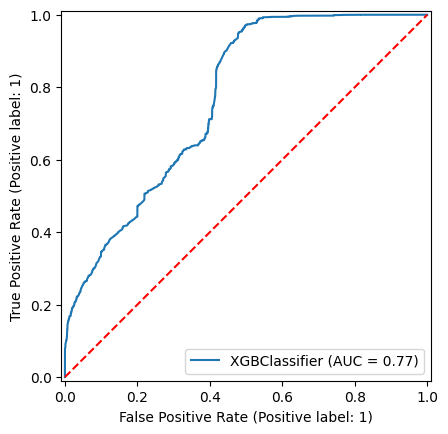

In [25]:
curva = RocCurveDisplay.from_estimator(modelo, X_teste, y_teste)
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.show()

##### 4.4.2. Extração do valor de AUC
---

In [26]:
auc_valor = curva.roc_auc
print(f'O valor de AUC do modelo é {auc_valor}.')

O valor de AUC do modelo é 0.7674554607744661.


##### 4.4.3. Análise do gráfico
---

## 5. Visualização da Relevância das Features
---

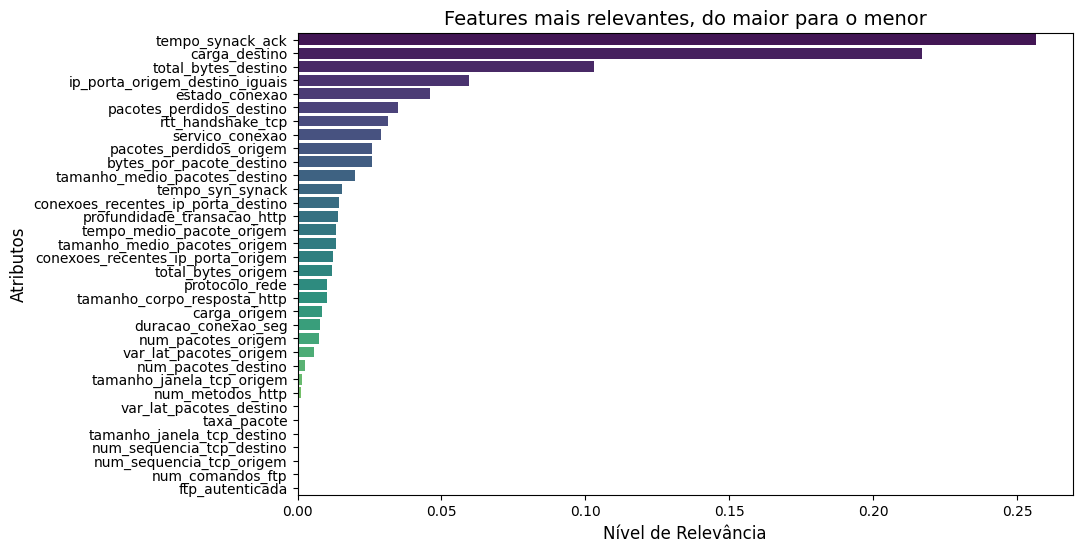

In [27]:
# Determinar as features de X_treino
relevancia_features = modelo.feature_importances_
cols_feature_treino = X_treino.columns

# Criação do df_relevancia para facilitar a criação do gráfico de barras
df_relevancia = pd.DataFrame({'Feature':cols_feature_treino, 'Relevância':relevancia_features})
df_relevancia = df_relevancia.sort_values(by='Relevância', ascending=False) # Organiza as barras à partir dos valores de relevância, do maior para o menor

# Criação do gráfico
plt.figure(figsize=(10, 6))
sns.barplot(x='Relevância', y='Feature', data=df_relevancia, palette='viridis', hue='Feature')

# Customização do gráfico
plt.title('Features mais relevantes, do maior para o menor', fontsize=14)
plt.xlabel('Nível de Relevância', fontsize=12)
plt.ylabel('Atributos', fontsize=12)
plt.show()

In [28]:
print(df_relevancia.head(10)) 

                           Feature  Relevância
23                tempo_synack_ack    0.256441
10                   carga_destino    0.217007
7              total_bytes_destino    0.103085
33  ip_porta_origem_destino_iguais    0.059647
3                   estado_conexao    0.046112
12        pacotes_perdidos_destino    0.035043
21               rtt_handshake_tcp    0.031374
2                  servico_conexao    0.028932
11         pacotes_perdidos_origem    0.026040
14        bytes_por_pacote_destino    0.025995
